In [30]:
# Langchain intro
print("hello")

hello


## Langchain version v1


In [31]:
import langchain
langchain.__version__

'1.4.0'

In [37]:
# import os
# from dotenv import load_dotenv
# load_dotenv()

# os.environ("OPENAI_API_KEY") =os.getenv("OPENAI_API_KEY")
# import os
# from dotenv import load_dotenv

# load_dotenv()

# os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
import os
from dotenv import load_dotenv

load_dotenv()

groq_api_key = os.getenv("GROQ_API_KEY")

print(groq_api_key is not None)

True


In [39]:
from langchain_groq import ChatGroq

model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

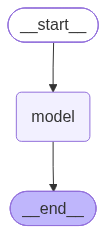

In [41]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq

model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

agent = create_agent(
    model=model,
    tools=[],
    system_prompt="You are a helpful agent."
)

agent

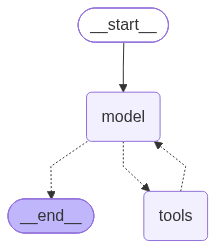

In [42]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq

model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

def get_weather(city: str) -> str:
    """Get the weather in a city."""
    return f"The weather in {city} is sunny"

agent = create_agent(
    model=model,
    tools=[get_weather],
    system_prompt="You are a helpful agent."
)

agent

In [43]:
response = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "What is the weather like in New York?"
        }
    ]
})

print(response)

{'messages': [HumanMessage(content='What is the weather like in New York?', additional_kwargs={}, response_metadata={}, id='5ed62279-5073-443b-ae75-e0e4d06f6b17'), AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is the weather like in New York?" We need to fetch weather using the provided function get_weather. We\'ll call it with city "New York".', 'tool_calls': [{'id': 'fc_48460e3f-20d6-4647-a4f4-12817bba0201', 'function': {'arguments': '{"city":"New York"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 64, 'prompt_tokens': 138, 'total_tokens': 202, 'completion_time': 0.134875775, 'completion_tokens_details': {'reasoning_tokens': 36}, 'prompt_time': 0.005521492, 'prompt_tokens_details': None, 'queue_time': 0.348720207, 'total_time': 0.140397267}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_f640395b96', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': 